In [10]:
import pandas as pd

df = pd.read_csv("../Cell_Painting_Median_Features_Median_doses.csv")

bioactive_cmpds = pd.read_csv("data/bioactive_compounds_with_assay_data.csv")

inactive_cmpds = pd.read_csv("data/compounds_with_assay_data.csv")
inactive_cmpds = inactive_cmpds[~inactive_cmpds.key14.isin(bioactive_cmpds.key14.unique())]

df

,InChICode_standardised,index,Metadata_mmoles_per_liter,Cells_AreaShape_Area,Cells_AreaShape_Center_X,Cells_AreaShape_Center_Y,Cells_AreaShape_Compactness,Cells_AreaShape_Eccentricity,Cells_AreaShape_EulerNumber,Cells_AreaShape_Extent,...,Nuclei_Texture_Variance_DNA_5_0,Nuclei_Texture_Variance_ER_10_0,Nuclei_Texture_Variance_ER_3_0,Nuclei_Texture_Variance_ER_5_0,Nuclei_Texture_Variance_Mito_10_0,Nuclei_Texture_Variance_Mito_3_0,Nuclei_Texture_Variance_Mito_5_0,Nuclei_Texture_Variance_RNA_10_0,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0
0,InChI=1S/C12H15N3O2S/c1-7(2)18-8-4-5-9-10(6-8)...,960.0,5.000000,1728.953125,-1.375000,-25.445312,-0.067918,-0.062396,0.0,0.026443,...,-0.218573,0.314918,0.222859,0.280258,0.192997,0.144917,0.168085,-0.332871,-0.314733,-0.313477
1,InChI=1S/C12H18N4O3/c1-7(2)5-16-10-9(11(17)15(...,1036.0,5.000000,-272.074219,11.464844,-1.628906,-0.001808,-0.006674,0.0,-0.001405,...,-0.135188,0.023860,-0.016903,-0.017773,-0.028029,-0.038308,-0.041455,-0.070389,-0.067789,-0.071673
2,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4942.5,4.973595,101.958984,15.673828,-2.314453,0.010687,0.013397,0.0,-0.003746,...,0.015253,-0.014119,0.035703,0.016875,-0.039304,-0.070028,-0.062892,-0.015647,-0.038908,-0.026464
3,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4944.5,4.912934,-109.708984,-10.203125,1.718750,0.025025,0.014627,0.0,-0.007164,...,-0.040388,0.046218,0.031759,0.037029,-0.051411,-0.083061,-0.071562,-0.024598,-0.052021,-0.043327
4,InChI=1S/C16H29N5O3/c1-12-9-20(13(2)10-22)16(2...,4949.5,5.012874,-234.222656,8.873047,3.308594,0.010192,0.005251,0.0,-0.003173,...,0.041850,-0.072889,-0.030955,-0.037623,-0.009460,0.004604,-0.010465,-0.031869,-0.025910,-0.014907
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30399,InChI=1S/C9H9N5OS2/c10-12-8(16)11-6-3-1-2-5(4-...,30588.0,5.000000,-226.027344,-18.847656,-0.511719,-0.005827,0.004864,0.0,0.003590,...,-0.201503,-0.114357,-0.123664,-0.127474,-0.069665,-0.056972,-0.044186,-0.019668,-0.091541,-0.062515
30400,InChI=1S/C9H9NO/c11-6-7-5-10-9-4-2-1-3-8(7)9/h...,30589.0,5.000000,254.769531,18.886719,-3.589844,0.027814,0.016943,0.0,-0.000781,...,-0.069652,-0.079942,-0.018155,-0.017759,-0.118369,-0.046322,-0.023926,0.033498,0.051214,0.016060
30401,InChI=1S/C9H9NO2/c10-8-3-1-2-7(6-8)4-5-9(11)12...,30590.0,5.000000,238.574219,-0.699219,6.625000,0.005228,0.008800,0.0,0.002336,...,0.042933,-0.107812,-0.107077,-0.138399,0.168811,0.216703,0.195851,-0.063656,-0.042877,-0.071681
30402,InChI=1S/C9H9NO3S/c1-6(11)5-14-8-3-2-7(4-10-8)...,30591.0,5.000000,-238.945312,5.476562,0.089844,0.018032,0.012711,0.0,-0.004635,...,0.081551,-0.070647,-0.095379,-0.102060,0.023423,0.049321,0.041996,0.023470,0.058959,0.065934


In [29]:
from rdkit import Chem

# Convert InChI to InChIKey
df["InChIKey"] = df["InChICode_standardised"].apply(lambda x: Chem.InchiToInchiKey(x) if pd.notna(x) else None)

df["InChIKey14"]= df["InChIKey"].str[:14]
df = df.drop_duplicates(subset="InChIKey14", keep=False)
df

,InChICode_standardised,index,Metadata_mmoles_per_liter,Cells_AreaShape_Area,Cells_AreaShape_Center_X,Cells_AreaShape_Center_Y,Cells_AreaShape_Compactness,Cells_AreaShape_Eccentricity,Cells_AreaShape_EulerNumber,Cells_AreaShape_Extent,...,Nuclei_Texture_Variance_ER_3_0,Nuclei_Texture_Variance_ER_5_0,Nuclei_Texture_Variance_Mito_10_0,Nuclei_Texture_Variance_Mito_3_0,Nuclei_Texture_Variance_Mito_5_0,Nuclei_Texture_Variance_RNA_10_0,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0,InChIKey,InChIKey14
0,InChI=1S/C12H15N3O2S/c1-7(2)18-8-4-5-9-10(6-8)...,960.0,5.0,1728.953125,-1.375000,-25.445312,-0.067918,-0.062396,0.0,0.026443,...,0.222859,0.280258,0.192997,0.144917,0.168085,-0.332871,-0.314733,-0.313477,SXJIZQPZESTWLD-UHFFFAOYSA-N,SXJIZQPZESTWLD
1,InChI=1S/C12H18N4O3/c1-7(2)5-16-10-9(11(17)15(...,1036.0,5.0,-272.074219,11.464844,-1.628906,-0.001808,-0.006674,0.0,-0.001405,...,-0.016903,-0.017773,-0.028029,-0.038308,-0.041455,-0.070389,-0.067789,-0.071673,NBLBCGUCPBXKOV-UHFFFAOYSA-N,NBLBCGUCPBXKOV
5,InChI=1S/C17H13NO3/c1-18-13-5-3-2-4-12(13)15(1...,5117.0,5.0,-459.175781,-8.570312,2.820312,-0.005516,-0.000954,0.0,-0.005567,...,-0.004288,0.025918,0.020560,0.004302,-0.008033,-0.056396,-0.026962,-0.039564,COBBNRKBTCBWQP-UHFFFAOYSA-N,COBBNRKBTCBWQP
72,InChI=1S/C24H27N3O3/c1-14-9-15(2)23(16(3)10-14...,17286.0,5.0,57.128906,4.636719,-7.753906,0.032394,0.016472,0.0,-0.002248,...,-0.045332,-0.036855,-0.046818,-0.062049,-0.070027,-0.019327,-0.034570,-0.035644,MCMSJVMUSBZUCN-YYDJUVGSSA-N,MCMSJVMUSBZUCN
188,"InChI=1S/C32H41NO2/c1-31(2,3)26-18-16-25(17-19...",28948.0,5.0,-2762.925781,258.902344,126.570312,-0.068141,-0.130738,0.0,-0.079006,...,1.745136,1.483225,0.531463,1.579915,1.493236,-0.703972,0.540142,0.358874,GUGOEEXESWIERI-UHFFFAOYSA-N,GUGOEEXESWIERI
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30399,InChI=1S/C9H9N5OS2/c10-12-8(16)11-6-3-1-2-5(4-...,30588.0,5.0,-226.027344,-18.847656,-0.511719,-0.005827,0.004864,0.0,0.003590,...,-0.123664,-0.127474,-0.069665,-0.056972,-0.044186,-0.019668,-0.091541,-0.062515,LHXWPDUWZAYBJV-UHFFFAOYSA-N,LHXWPDUWZAYBJV
30400,InChI=1S/C9H9NO/c11-6-7-5-10-9-4-2-1-3-8(7)9/h...,30589.0,5.0,254.769531,18.886719,-3.589844,0.027814,0.016943,0.0,-0.000781,...,-0.018155,-0.017759,-0.118369,-0.046322,-0.023926,0.033498,0.051214,0.016060,IVYPNXXAYMYVSP-UHFFFAOYSA-N,IVYPNXXAYMYVSP
30401,InChI=1S/C9H9NO2/c10-8-3-1-2-7(6-8)4-5-9(11)12...,30590.0,5.0,238.574219,-0.699219,6.625000,0.005228,0.008800,0.0,0.002336,...,-0.107077,-0.138399,0.168811,0.216703,0.195851,-0.063656,-0.042877,-0.071681,JNXMJSYJCFTLJB-SNAWJCMRSA-N,JNXMJSYJCFTLJB
30402,InChI=1S/C9H9NO3S/c1-6(11)5-14-8-3-2-7(4-10-8)...,30591.0,5.0,-238.945312,5.476562,0.089844,0.018032,0.012711,0.0,-0.004635,...,-0.095379,-0.102060,0.023423,0.049321,0.041996,0.023470,0.058959,0.065934,LRBIKSYRCFHKBN-UHFFFAOYSA-N,LRBIKSYRCFHKBN


In [30]:
bioactive_cmpds = bioactive_cmpds.drop_duplicates(subset="key14", keep=False)
bioactive_cmpds

,key14,BROAD_ID,Metadata_pert_id
0,JEFNGIWYLXETLU,BRD-A01717918-001-05-5,BRD-A01717918
1,HKGJEZIGDHFJFL,BRD-A02481876-001-08-1,BRD-A02481876
2,TXQUPVHAFRNVNR,BRD-A02927672-001-06-3,BRD-A02927672
3,QCGHTRAZOATGMB,BRD-A03764094-001-09-3,BRD-A03764094
4,CAOHKWDKHJCSRC,BRD-A05883068-001-05-9,BRD-A05883068
...,...,...,...
12788,OFUDZKKOKPGXOH,BRD-A77218119-001-02-7,BRD-A77218119
12789,GAMRBCZMOOMBSQ,BRD-K77817104-001-01-3,BRD-K77817104
12790,XPJOMFBGKIABQW,BRD-K87696786-003-01-0,BRD-K87696786
12791,FWSWMSADSURGNY,BRD-A59528596-001-06-4,BRD-A59528596


In [31]:
inactive_cmpds = inactive_cmpds.drop_duplicates(subset="key14", keep=False)
inactive_cmpds

,key14,BROAD_ID,Metadata_pert_id
1,TYLHRPBDFWODNS,BRD-A02214146-001-06-4,BRD-A02214146
11,NVISMUCUSDUQFO,BRD-A10134527-001-05-5,BRD-A10134527
15,AJLVNTLWHVMFEJ,BRD-A17635048-001-06-2,BRD-A17635048
21,DCLOSCFPNJJECN,BRD-A23193246-001-05-6,BRD-A23193246
29,AJFINBIBIHGQFB,BRD-A37796306-001-05-7,BRD-A37796306
...,...,...,...
25738,ZBXDOQWPGBISAR,BRD-K16551401-003-01-8,BRD-K16551401
25739,KRVOJOCLBAAKSJ,BRD-A66927094-001-01-7,BRD-A66927094
25743,VDVJGIYXDVPQLP,BRD-K52148119-001-01-5,BRD-K52148119
25744,URMVDBRFNKFWQR,BRD-K57070101-001-06-5,BRD-K57070101


In [35]:
# Find common key14 values
common_keys = set(bioactive_cmpds['key14']) & set(inactive_cmpds['key14'])

# Drop rows with these keys from both dataframes
bioactive_cmpds = bioactive_cmpds[~bioactive_cmpds['key14'].isin(common_keys)]
inactive_cmpds = inactive_cmpds[~inactive_cmpds['key14'].isin(common_keys)]


In [36]:
bioactive_df = df[df.InChIKey14.isin(bioactive_cmpds.key14.unique())].reset_index(drop=True)
inactive_df = df[df.InChIKey14.isin(inactive_cmpds.key14.unique())].reset_index(drop=True)

In [37]:
bioactive_df.InChIKey14.nunique()

4670

In [38]:
inactive_df.InChIKey14.nunique()

5603

In [40]:
bioactive_df

,InChICode_standardised,index,Metadata_mmoles_per_liter,Cells_AreaShape_Area,Cells_AreaShape_Center_X,Cells_AreaShape_Center_Y,Cells_AreaShape_Compactness,Cells_AreaShape_Eccentricity,Cells_AreaShape_EulerNumber,Cells_AreaShape_Extent,...,Nuclei_Texture_Variance_ER_3_0,Nuclei_Texture_Variance_ER_5_0,Nuclei_Texture_Variance_Mito_10_0,Nuclei_Texture_Variance_Mito_3_0,Nuclei_Texture_Variance_Mito_5_0,Nuclei_Texture_Variance_RNA_10_0,Nuclei_Texture_Variance_RNA_3_0,Nuclei_Texture_Variance_RNA_5_0,InChIKey,InChIKey14
0,InChI=1S/C10H10FN3/c11-10-4-2-1-3-8(10)6-14-7-...,102.0,5.000000,561.269531,-13.488281,-11.742188,0.057042,0.024241,0.0,-0.022071,...,-0.176864,-0.143412,0.004736,-0.028997,-0.020507,-0.225685,-0.179854,-0.174467,MOBHPISBSWMGDW-UHFFFAOYSA-N,MOBHPISBSWMGDW
1,InChI=1S/C10H10N2O/c1-8-7-10(13)12(11-8)9-5-3-...,104.0,14.351386,83.085938,6.679688,-2.980469,-0.003898,0.002892,0.0,-0.001432,...,-0.073432,-0.070867,-0.037841,-0.081784,-0.085790,-0.083668,-0.064161,-0.074736,QELUYTUMUWHWMC-UHFFFAOYSA-N,QELUYTUMUWHWMC
2,"InChI=1S/C10H10N2O2S/c1-15(13,14)12-9-6-2-4-8-...",106.0,5.000000,-259.365942,9.778986,-2.003623,0.005086,0.002094,0.0,0.000904,...,0.042628,0.029429,0.014291,-0.011005,0.001697,0.019642,0.045408,0.039712,XYEPUTZVZYUENX-UHFFFAOYSA-N,XYEPUTZVZYUENX
3,InChI=1S/C10H10N2O2S/c1-2-13-8-6-4-3-5-7(8)9-1...,107.0,5.000000,-424.066406,-17.320312,-6.425781,0.012511,0.014761,0.0,-0.005774,...,-0.010486,-0.024779,-0.101447,-0.167037,-0.118618,-0.214162,-0.172930,-0.180283,VTXLLACKNPVAJW-UHFFFAOYSA-N,VTXLLACKNPVAJW
4,InChI=1S/C10H10N2O2S/c1-3-14-10(13)8-4-7(5-11)...,108.0,5.000000,-194.304688,-1.167969,-1.296875,0.005372,0.000162,0.0,-0.004308,...,-0.037270,-0.045723,-0.037489,-0.053836,-0.067600,-0.006845,0.007117,0.001893,YMUNSRSFLNLDAF-UHFFFAOYSA-N,YMUNSRSFLNLDAF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4665,InChI=1S/C9H9F6N3OS2/c1-3-20-6-18-17-5(21-6)16...,30575.0,5.000000,-127.328125,28.062500,-19.843750,0.056111,0.020871,0.0,-0.007671,...,0.061648,0.109512,-0.183137,-0.295725,-0.295652,-0.054505,-0.098247,-0.066849,CACIMFREAFKQBY-UHFFFAOYSA-N,CACIMFREAFKQBY
4666,"InChI=1S/C9H9N3O2S2/c10-7-1-3-8(4-2-7)16(13,14...",30579.0,5.000000,185.621094,6.777344,-7.761719,0.020688,0.007500,0.0,-0.009577,...,-0.026654,-0.007774,-0.088286,-0.052080,-0.073599,-0.055808,-0.070133,-0.061253,JNMRHUJNCSQMMB-UHFFFAOYSA-N,JNMRHUJNCSQMMB
4667,InChI=1S/C9H9N3OS/c1-13-7-4-2-6(3-5-7)8-10-9(1...,30582.0,5.000000,-458.695312,-3.914062,7.148438,0.000335,0.005566,0.0,0.004002,...,-0.075234,-0.053247,0.048383,0.126505,0.122444,-0.076079,-0.050118,-0.057485,USRWSSVQAGNWRI-UHFFFAOYSA-N,USRWSSVQAGNWRI
4668,InChI=1S/C9H9N5OS2/c10-12-8(16)11-6-3-1-2-5(4-...,30588.0,5.000000,-226.027344,-18.847656,-0.511719,-0.005827,0.004864,0.0,0.003590,...,-0.123664,-0.127474,-0.069665,-0.056972,-0.044186,-0.019668,-0.091541,-0.062515,LHXWPDUWZAYBJV-UHFFFAOYSA-N,LHXWPDUWZAYBJV


INFO: Pandarallel will run on 40 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


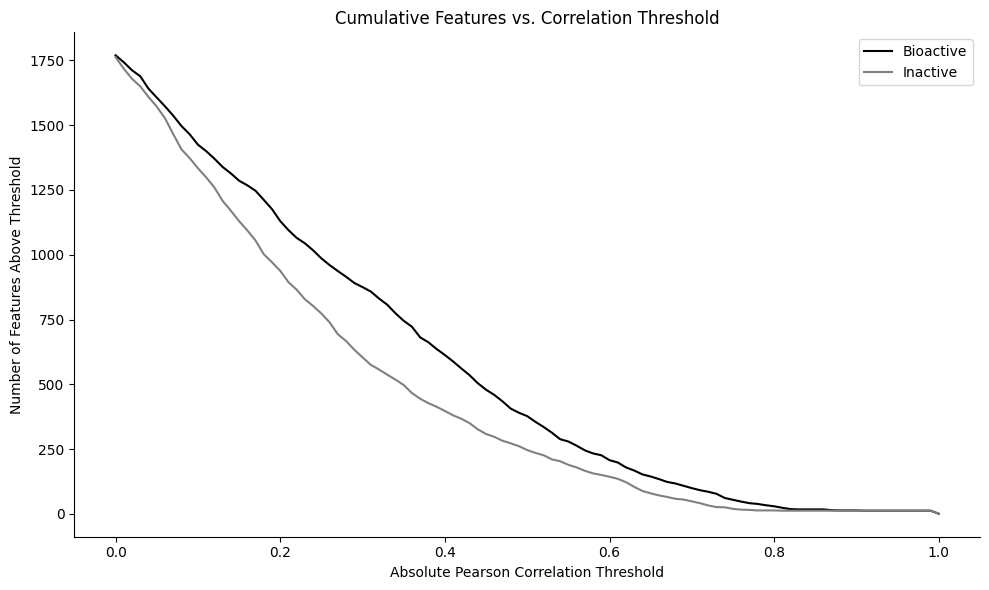

In [51]:
import numpy as np
from pandarallel import pandarallel
import pandas as pd
import matplotlib.pyplot as plt

# Initialize pandarallel
pandarallel.initialize(progress_bar=True)

def get_abs_correlations(df):
    features = df.columns[3:-2]
    cell_count = "Cells_Number_Object_Number"
    
    corr = df[features].parallel_apply(lambda col: col.corr(df[cell_count]))
    return corr.abs()

# Calculate correlations
bio_corr = get_abs_correlations(bioactive_df)
inactive_corr = get_abs_correlations(inactive_df)

# Thresholds from 0 to 1
thresholds = np.linspace(0, 1, 101)

# Count features above each threshold
bio_counts = [sum(bio_corr > t) for t in thresholds]
inactive_counts = [sum(inactive_corr > t) for t in thresholds]

# Plot cumulative curves
plt.figure(figsize=(10, 6))
plt.plot(thresholds, bio_counts, label="Bioactive", color='black')
plt.plot(thresholds, inactive_counts, label="Inactive", color='gray')
plt.xlabel("Absolute Pearson Correlation Threshold")
plt.ylabel("Number of Features Above Threshold")
plt.title("Cumulative Features vs. Correlation Threshold")
plt.legend()
sns.despine()
plt.tight_layout()
plt.show()
